## **დავალებები: Data Exploration**

In [17]:
import pandas as pd 
from sklearn.preprocessing import OneHotEncoder

###  Wine Quality Dataset (UCI)

In [2]:
# URLs for red and white wine datasets
red_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
white_wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
red_wine = pd.read_csv(red_wine_url, sep=";")
white_wine = pd.read_csv(white_wine_url, sep=";")
red_wine["type"] = "red"
white_wine["type"] = "white"
df_wine = pd.concat([red_wine, white_wine])
df_wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


### მონაცემების ანალიზი
  - გამოიყენეთ `.info()`, `.describe()` მონაცემთა შიგთავსზე საწყისი შთაბეჭდილების შესაქმნელად.
  - შეამოწმეთ გვაქვს თუ არა duplicated მნიშვნელობები, გადაწყვიტეთ, როგორ მოიქცევით ამ მნიშვნელობებთან მიმართებაში.
  - შეამოწმეთ რომელ სვეტებშია `None` მნიშვნელობები
  - გადაწყვიტეთ, როგორ მოიქცევით ამ `None` მნიშვნელობებთან მიმართებაში - იქნება ეს მნიშვნელობების შევსება, წაშლა თუ სხვა მეთოდის გამოყენება.
  - `type` სვეტის კოდირება
  - საშუალო `"alcohol"` მნიშვნელობა მაღალი და დაბალი ხარისხის ღვინოებში
  - ააგე scatter plot `"alcohol"` vs `"density"` ფერით `"quality"`
  - იპოვე საშუალო `"citric acid"` `"type"` და `"quality"`-ის მიხედვით
  - დაამატეთ ახალი სვეტი `"total acidity"`, რომლის მნიშვნელობა არის `fixed acidity`-ის და `volatile acidity`-ის მნიშვნელობების ჯამი
  - დაამატე ახალი სვეტი `"acidity_ratio" = volatile_acidity / fixed_acidity`
  - კორელაციური ანალიზი: გამოიკვლიეთ, რომელ მახასიათებლებზეა დამოკიდებული სვეტი `"quality"`
  - ააგეთ გრაფიკი, რომელიც აჩვენებს თითოეული ჯგუფისთვის (ხარისხისთვის) მონაცემების ალკოჰოლის რაოდენობის განაწილება
  - ააგეთ გრაფიკი, რომელიც აჩვენებს თითოეული კატეგორიის (ხარისხის) ჩანაწერების რაოდენობას
  - გადააკეთე `"quality"` კატეგორიულ სვეტად (`pd.cut`)
  - გამოიყენეთ StandardScaler რიცხვითი მონაცემების სკალირებისთვის

In [3]:
#   - გამოიყენეთ `.info()`, `.describe()` მონაცემთა შიგთავსზე საწყისი შთაბეჭდილების შესაქმნელად.
data = df_wine
data.info()
data.describe()

<class 'pandas.DataFrame'>
Index: 6497 entries, 0 to 4897
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  type                  6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 710.6 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [7]:
#   - შეამოწმეთ გვაქვს თუ არა duplicated მნიშვნელობები, გადაწყვიტეთ, როგორ მოიქცევით ამ მნიშვნელობებთან მიმართებაში.
data.duplicated().sum()
data.drop_duplicates(inplace=True)
data.duplicated().sum()

np.int64(0)

In [14]:
#   - შეამოწმეთ რომელ სვეტებშია `None` მნიშვნელობები

result = [
    col for col in data.columns
    if data[col].isna().any() or (data[col] == "None").any()
]

result

[]

In [29]:
#   - საშუალო `"alcohol"` მნიშვნელობა მაღალი და დაბალი ხარისხის ღვინოებში

data.groupby("quality").agg(
    MEAN_ALCOHOL = ("alcohol","mean")
).reset_index()

,quality,MEAN_ALCOHOL
0,3,10.215000
1,4,10.215049
2,5,9.872211
3,6,10.649060
4,7,11.511020
5,8,11.912162
6,9,12.180000


<Axes: xlabel='alcohol', ylabel='density'>

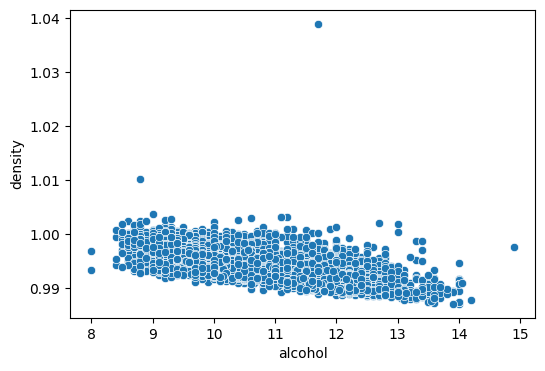

In [ ]:
#   - ააგე scatter plot `"alcohol"` vs `"density"` ფერით `"quality"`
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.scatterplot(data = data, x="alcohol", y = "density")

In [36]:
#   - იპოვე საშუალო `"citric acid"` `"type"` და `"quality"`-ის მიხედვით
data.groupby(["type","quality"]).agg(
    MEAN_CITRIC_ACID = ("citric acid","mean")
).reset_index()

# data

,type,quality,MEAN_CITRIC_ACID
0,red,3,0.171000
1,red,4,0.174151
2,red,5,0.244523
3,red,6,0.279364
4,red,7,0.371856
5,red,8,0.382941
6,white,3,0.336000
7,white,4,0.305229
8,white,5,0.335957
9,white,6,0.338227


In [37]:
#   - დაამატეთ ახალი სვეტი `"total acidity"`, რომლის მნიშვნელობა არის `fixed acidity`-ის და `volatile acidity`-ის მნიშვნელობების ჯამი

data["total acidity"] = data["fixed acidity"] + data["volatile acidity"]

In [ ]:
#   - დაამატე ახალი სვეტი `"acidity_ratio" = volatile_acidity / fixed_acidity`

data["acidity_ratio"] = data["volatile acidity"] + data["fixed acidity"]

<Axes: >

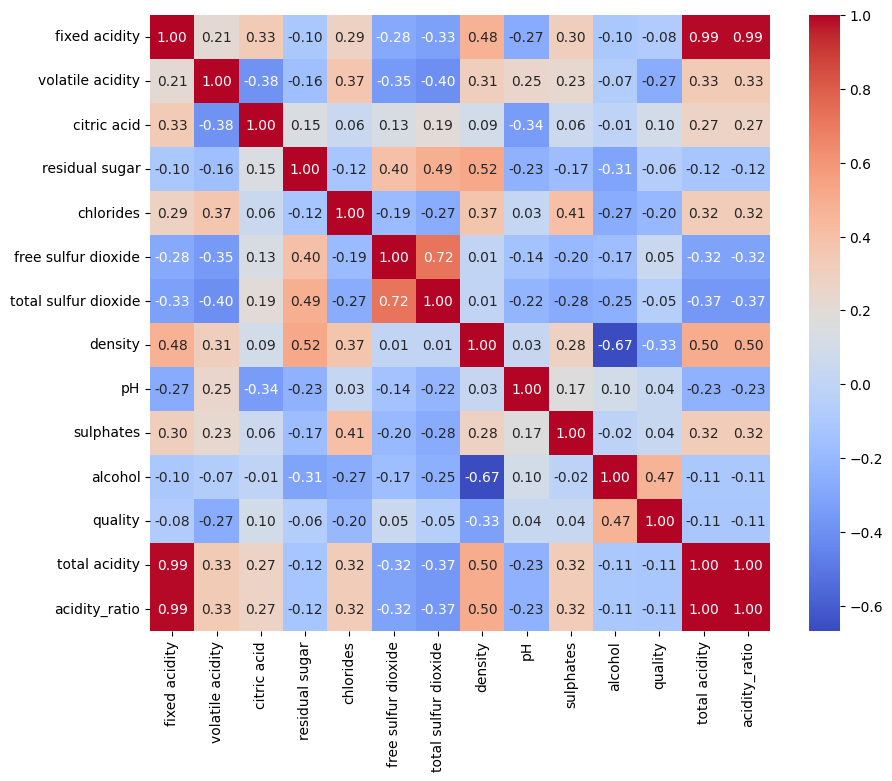

In [ ]:
#   - კორელაციური ანალიზი: გამოიკვლიეთ, რომელ მახასიათებლებზეა დამოკიდებული სვეტი `"quality"`

num = data.select_dtypes(include="number").columns

data_corr = data[num].corr()
plt.figure(figsize=(10,8))
sns.heatmap(data_corr, annot=True,cmap='coolwarm',fmt='.2f')
# alokoholi

<Axes: xlabel='quality', ylabel='MEAN_ALCOHOL'>

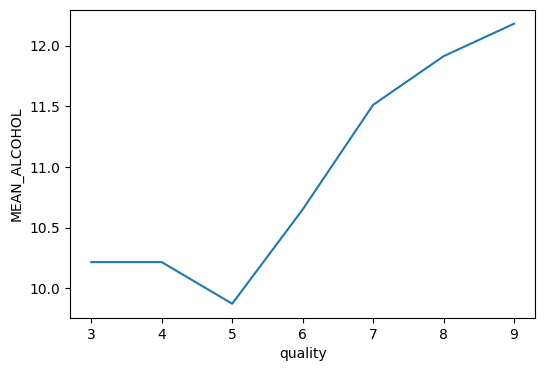

In [52]:
#   - ააგეთ გრაფიკი, რომელიც აჩვენებს თითოეული ჯგუფისთვის (ხარისხისთვის) მონაცემების ალკოჰოლის რაოდენობის განაწილება
da = data.groupby("quality").agg(
    MEAN_ALCOHOL = ("alcohol","mean")
).reset_index()
da
plt.figure(figsize=(6,4))
sns.lineplot(data= da, x = "quality", y= "MEAN_ALCOHOL"  )

In [ ]:
#   - გადააკეთე `"quality"` კატეგორიულ სვეტად (`pd.cut`)
data
bins = [0, 3, 5, 10]
labels = ["Low", "Medium", "High"]
data["quality_cat"] = pd.cut(data["quality"], bins=bins, labels=labels)